# Lesson 07 | 六症状朴素贝叶斯分类

本 Notebook 使用课程原始拆分数据，训练 BernoulliNB 并验证 Worksheet 的关键指标。**测试标签来自教师提供的文件，属于固定教学测试复现。**

运行方式：在项目根目录启动 `jupyter lab`，打开本文件，依次运行所有单元格。

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
if not (root / "src" / "naive_bayes.py").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))
from naive_bayes import run
print("项目根目录:", root)

项目根目录: /mnt/data/lesson-07-naive-bayes


## 1. 数据检查
训练、验证和测试记录分别为 72、24、24。模型只使用六项二元症状，标签为 `bladder_inflammation`。

In [2]:
train = pd.read_csv(root / "data/train.csv")
validation = pd.read_csv(root / "data/validation.csv")
print("train:",train.shape,"validation:",validation.shape)
display(train.head())

train: (72, 10) validation: (24, 10)


,sample_id,temperature_c,fever_ge_38,nausea,lumbar_pain,urine_pushing,micturition_pain,burning_urethra,bladder_inflammation,nephritis
0,A114,41.2,1,0,1,1,0,1,0,1
1,A012,36.6,0,0,1,0,0,0,0,0
2,A073,40.0,1,1,1,1,1,0,1,1
3,A108,41.1,1,0,0,0,0,0,0,0
4,A086,40.4,1,1,1,1,1,0,1,1


## 2. 训练、阈值选择与固定测试复现
训练集估计参数；验证集按照敏感度至少 0.90、特异度最大、接近 0.5 的规则选择阈值；最后使用教师标签核对固定测试集。

In [3]:
results = run()
print(json.dumps(results, ensure_ascii=False, indent=2))

{
  "sample_counts": {
    "train": 72,
    "validation": 24,
    "test": 24
  },
  "train_positive": 35,
  "threshold": 0.5,
  "validation": {
    "n": 24,
    "TN": 12,
    "FP": 0,
    "FN": 0,
    "TP": 12,
    "accuracy": 1.0,
    "sensitivity": 1.0,
    "specificity": 1.0,
    "precision": 1.0,
    "f1": 1.0,
    "log_loss": 0.0872138108339317
  },
  "test": {
    "n": 24,
    "TN": 12,
    "FP": 0,
    "FN": 0,
    "TP": 12,
    "accuracy": 1.0,
    "sensitivity": 1.0,
    "specificity": 1.0,
    "precision": 1.0,
    "f1": 1.0,
    "log_loss": 0.07449229980495921
  },
  "prior_validation": {
    "n": 24,
    "TN": 12,
    "FP": 0,
    "FN": 12,
    "TP": 0,
    "accuracy": 0.5,
    "sensitivity": 0.0,
    "specificity": 1.0,
    "precision": 0.0,
    "f1": 0.0,
    "log_loss": 0.6935331319492363
  },
  "query_000111_probability": 0.9865759062601746,
  "duplicate_feature": [
    {
      "extra_lumbar_copies": 0,
      "n": 24,
      "TN": 12,
      "FP": 0,
      "FN": 0,
      

## 3. 输出证据
下列图和表由上述代码重新生成，存放在 `outputs/`。

,threshold,n,TN,FP,FN,TP,accuracy,sensitivity,specificity,precision,f1,log_loss,eligible
0,0.05,24,4,8,0,12,0.666667,1.000000,0.333333,0.600000,0.750000,0.087214,True
1,0.10,24,7,5,0,12,0.791667,1.000000,0.583333,0.705882,0.827586,0.087214,True
2,0.20,24,12,0,0,12,1.000000,1.000000,1.000000,1.000000,1.000000,0.087214,True
3,0.30,24,12,0,0,12,1.000000,1.000000,1.000000,1.000000,1.000000,0.087214,True
4,0.50,24,12,0,0,12,1.000000,1.000000,1.000000,1.000000,1.000000,0.087214,True
5,0.70,24,12,0,1,11,0.958333,0.916667,1.000000,1.000000,0.956522,0.087214,True
6,0.80,24,12,0,1,11,0.958333,0.916667,1.000000,1.000000,0.956522,0.087214,True
7,0.90,24,12,0,2,10,0.916667,0.833333,1.000000,1.000000,0.909091,0.087214,False
8,0.95,24,12,0,6,6,0.750000,0.500000,1.000000,1.000000,0.666667,0.087214,False


,extra_lumbar_copies,n,TN,FP,FN,TP,accuracy,sensitivity,specificity,precision,f1,log_loss
0,0,24,12,0,0,12,1.00,1.000000,1.000000,1.000,1.0,0.087214
1,1,24,12,0,0,12,1.00,1.000000,1.000000,1.000,1.0,0.070425
2,5,24,11,1,5,7,0.75,0.583333,0.916667,0.875,0.7,0.385377


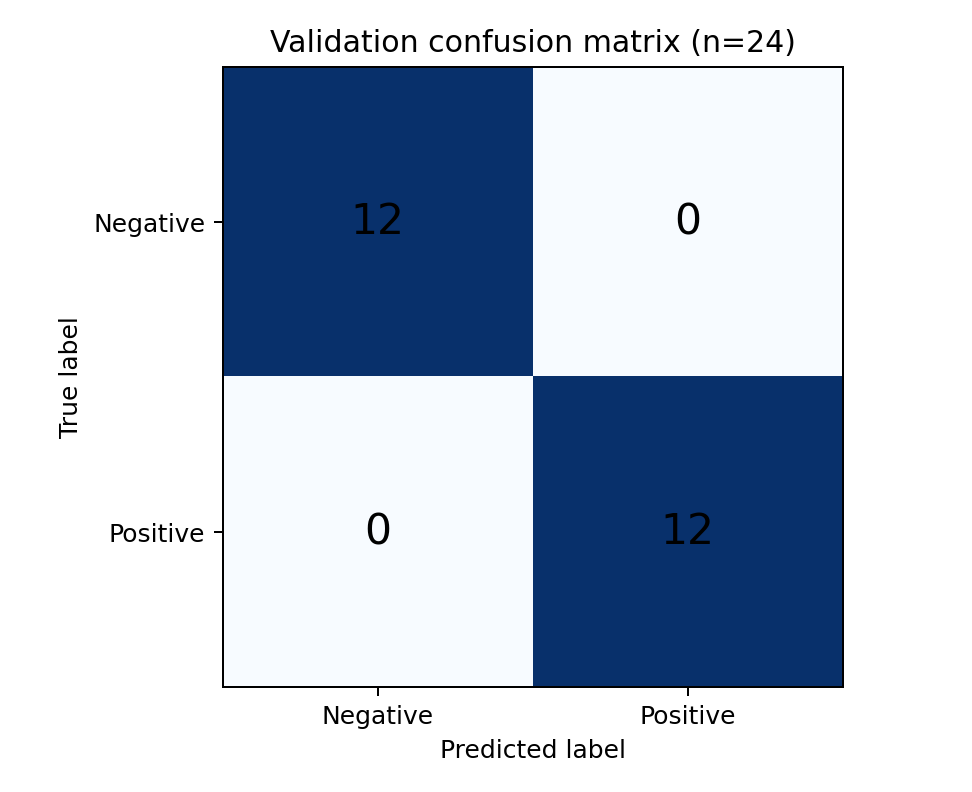

In [4]:
display(pd.read_csv(root / "outputs/threshold_grid.csv"))
display(pd.read_csv(root / "outputs/duplicate_feature.csv"))
display(Image(filename=str(root / "outputs/validation_confusion_matrix.png")))

## 4. 解释与局限
- 120 条数据是专家构造的教学记录，不是独立临床患者样本。
- 验证/测试的六项二元症状组合均可在训练数据中找到，因此高准确率不能证明对未见组合的泛化能力。
- 重复腰痛特征会改变模型输出，说明条件独立假设可能影响概率质量。
- 本项目的测试标签在课程资料中可见，因此不应把结果宣传为完全盲法的外部测试。